In [1]:
import pandas as pd
import numpy as np
print("Setup works!", pd.__version__)

Setup works! 3.0.6


In [3]:
from sklearn.datasets import fetch_openml

freq = fetch_openml(data_id=41214, as_frame=True, parser="pandas").frame
sev = fetch_openml(data_id=41215, as_frame=True, parser="pandas").frame
freq["IDpol"] = freq["IDpol"].astype(int)
sev["IDpol"] = sev["IDpol"].astype(int)
print(freq.shape, sev.shape)
freq.head()

(678013, 12) (26639, 2)


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82
1,3,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82
2,5,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22
3,10,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72
4,11,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72


In [4]:
# Cap extreme values so a few outliers don't dominate the models
freq["ClaimNb"] = freq["ClaimNb"].astype(int).clip(upper=4)
freq["Exposure"] = freq["Exposure"].clip(upper=1)

# Remove stray quote marks from text columns (you can see 'Regular' with quotes)
for col in ["Area", "VehBrand", "VehGas", "Region"]:
    freq[col] = freq[col].astype(str).str.strip("'")

# Some policies have several claim rows, so total them per policy
sev = sev.groupby("IDpol", as_index=False)["ClaimAmount"].sum()
sev["ClaimAmount"] = sev["ClaimAmount"].clip(upper=200_000)

# Join the two tables; policies with no claim get an amount of 0
df = freq.merge(sev, on="IDpol", how="left")
df["ClaimAmount"] = df["ClaimAmount"].fillna(0)

print(df.shape)
print(df.isna().sum().sum(), "missing values")
df.describe().T

(678013, 13)
0 missing values


,count,mean,std,min,25%,50%,75%,max
IDpol,678013.0,2.621857e+06,1.641783e+06,1.000000,1157951.00,2272152.00,4046274.00,6114330.0
ClaimNb,678013.0,5.317892e-02,2.379544e-01,0.000000,0.00,0.00,0.00,4.0
Exposure,678013.0,5.285446e-01,3.640807e-01,0.002732,0.18,0.49,0.99,1.0
VehPower,678013.0,6.454631e+00,2.050906e+00,4.000000,5.00,6.00,7.00,15.0
VehAge,678013.0,7.044265e+00,5.666232e+00,0.000000,2.00,6.00,11.00,100.0
DrivAge,678013.0,4.549912e+01,1.413744e+01,18.000000,34.00,44.00,55.00,100.0
BonusMalus,678013.0,5.976150e+01,1.563666e+01,50.000000,50.00,50.00,64.00,230.0
Density,678013.0,1.792422e+03,3.958647e+03,1.000000,92.00,393.00,1658.00,27000.0
ClaimAmount,678013.0,7.694784e+01,1.611088e+03,0.000000,0.00,0.00,0.00,200000.0


In [5]:
import sqlite3

conn = sqlite3.connect("../data/insurance.db")
df.to_sql("policies", conn, if_exists="replace", index=False)

pd.read_sql("SELECT COUNT(*) AS n_policies, SUM(ClaimNb) AS total_claims FROM policies", conn)


,n_policies,total_claims
0,678013,36056


In [6]:
q1 = """
SELECT SUM(ClaimNb) * 1.0 / SUM(Exposure) AS frequency,
       SUM(ClaimAmount) / SUM(Exposure)   AS loss_cost
FROM policies
"""
pd.read_sql(q1, conn)


,frequency,loss_cost
0,0.100614,145.584389


In [7]:
q_age = """
SELECT CASE WHEN DrivAge < 25 THEN '18-24'
            WHEN DrivAge < 35 THEN '25-34'
            WHEN DrivAge < 50 THEN '35-49'
            WHEN DrivAge < 65 THEN '50-64'
            ELSE '65+' END AS age_band,
       ROUND(SUM(Exposure), 0)            AS exposure,
       SUM(ClaimNb) * 1.0 / SUM(Exposure) AS frequency,
       SUM(ClaimAmount) / SUM(Exposure)   AS loss_cost
FROM policies
GROUP BY age_band
ORDER BY MIN(DrivAge)
"""
age = pd.read_sql(q_age, conn)
age

,age_band,exposure,frequency,loss_cost
0,18-24,12489.0,0.189288,435.847326
1,25-34,64573.0,0.099051,151.461712
2,35-49,131169.0,0.098301,132.702357
3,50-64,102153.0,0.096424,127.215881
4,65+,47977.0,0.094878,136.445380


In [8]:
q_bm = """
SELECT CASE WHEN BonusMalus < 60 THEN '50-59'
            WHEN BonusMalus < 80 THEN '60-79'
            WHEN BonusMalus < 100 THEN '80-99'
            ELSE '100+' END AS bonus_malus_band,
       ROUND(SUM(Exposure), 0)            AS exposure,
       SUM(ClaimNb) * 1.0 / SUM(Exposure) AS frequency,
       SUM(ClaimAmount) / SUM(Exposure)   AS loss_cost
FROM policies
GROUP BY bonus_malus_band
ORDER BY MIN(BonusMalus)
"""
bm = pd.read_sql(q_bm, conn)

q_veh = """
SELECT CASE WHEN VehAge < 3 THEN '0-2'
            WHEN VehAge < 6 THEN '3-5'
            WHEN VehAge < 10 THEN '6-9'
            ELSE '10+' END AS veh_age_band,
       ROUND(SUM(Exposure), 0)            AS exposure,
       SUM(ClaimNb) * 1.0 / SUM(Exposure) AS frequency,
       SUM(ClaimAmount) / SUM(Exposure)   AS loss_cost
FROM policies
GROUP BY veh_age_band
ORDER BY MIN(VehAge)
"""
veh = pd.read_sql(q_veh, conn)

display(bm)
display(veh)

,bonus_malus_band,exposure,frequency,loss_cost
0,50-59,264962.0,0.082306,104.166592
1,60-79,53777.0,0.128679,207.122586
2,80-99,29809.0,0.143075,233.269003
3,100+,9811.0,0.312193,660.399927


,veh_age_band,exposure,frequency,loss_cost
0,0-2,79138.0,0.137785,149.223638
1,3-5,72021.0,0.093625,143.405101
2,6-9,78032.0,0.099511,156.605620
3,10+,129169.0,0.082403,137.911870


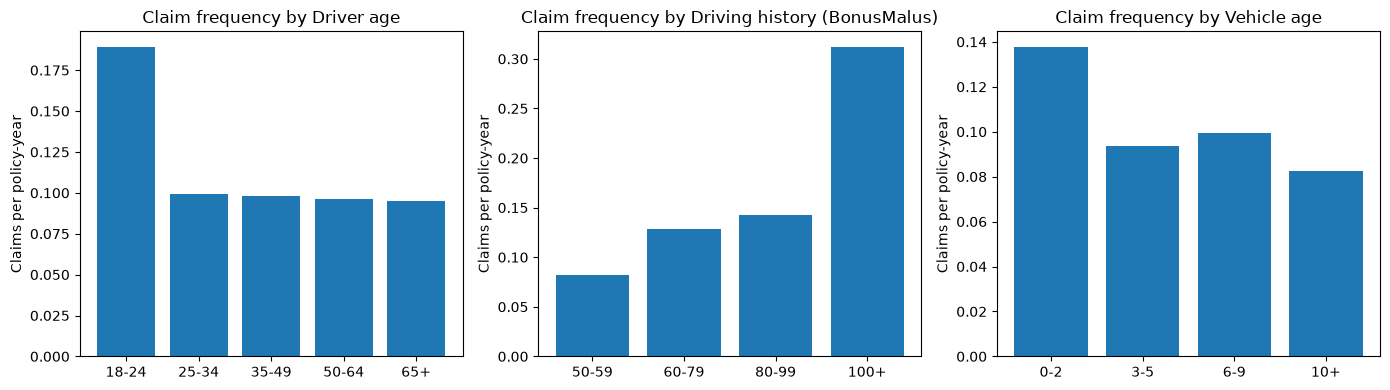

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, d, col, title in zip(axes, [age, bm, veh],
                             ["age_band", "bonus_malus_band", "veh_age_band"],
                             ["Driver age", "Driving history (BonusMalus)", "Vehicle age"]):
    ax.bar(d[col], d["frequency"])
    ax.set_title(f"Claim frequency by {title}")
    ax.set_ylabel("Claims per policy-year")
plt.tight_layout()
plt.show()

## Key findings: exploratory analysis

**Overall**: Across 678,013 policies, the claim frequency is 0.10 claims per
policy-year (about 1 claim every 10 years), and the loss cost is $145.58 per
policy-year.

**1. Driver age:** The 18-24 group has the highest claim frequency
([x.xx]), which is [X] times the frequency of the [age band] group ([x.xx]).

**2. Driving history (BonusMalus):** Policies in the [band] band have a claim
frequency of [x.xx], [X] times higher than the [band] band. This is the
strongest single predictor of claims in the data.

**3. Vehicle age:** [Describe the trend: do older vehicles claim more, less,
or about the same? Give the numbers for the lowest and highest bands.]

**4. Frequency vs. cost:** [Does a group with high frequency also have high
loss cost? Mention one band where they differ, if any.]

**What this means:** Claim risk varies a lot across customer groups, so a
single price for everyone would be unfair and unprofitable. This motivates
building a model that segments policies by risk.

In [10]:
overall = pd.read_sql("""
SELECT COUNT(*) AS n,
       SUM(ClaimNb) * 1.0 / SUM(Exposure) AS f,
       SUM(ClaimAmount) / SUM(Exposure)   AS l
FROM policies
""", conn).iloc[0]

def hi_lo(d, col):
    hi = d.loc[d["frequency"].idxmax()]
    lo = d.loc[d["frequency"].idxmin()]
    return hi[col], hi["frequency"], lo[col], lo["frequency"], hi["frequency"] / lo["frequency"]

a = hi_lo(age, "age_band")
b = hi_lo(bm, "bonus_malus_band")

v_first, v_last = veh.iloc[0], veh.iloc[-1]
pct = (v_last["frequency"] / v_first["frequency"] - 1) * 100
direction = "increase" if pct > 0 else "decrease"

top_freq = age.loc[age["frequency"].idxmax(), "age_band"]
top_cost = age.loc[age["loss_cost"].idxmax(), "age_band"]
if top_freq == top_cost:
    link = f"The {top_freq} age band has both the highest claim frequency and the highest loss cost."
else:
    link = (f"The {top_freq} age band has the highest claim frequency, but the {top_cost} "
            f"age band has the highest loss cost, so frequent claimers are not always the costliest.")

text = f"""## Key findings: exploratory analysis

**Overall:** Across {int(overall["n"]):,} policies, the claim frequency is {overall["f"]:.2f} claims per policy-year (about 1 claim every {1/overall["f"]:.0f} years), and the loss cost is {overall["l"]:.2f} per policy-year.

**1. Driver age:** The {a[0]} group has the highest claim frequency ({a[1]:.2f}), which is {a[4]:.1f} times the frequency of the {a[2]} group ({a[3]:.2f}).

**2. Driving history (BonusMalus):** Policies in the {b[0]} band have a claim frequency of {b[1]:.2f}, which is {b[4]:.1f} times higher than the {b[2]} band ({b[3]:.2f}).

**3. Vehicle age:** Claim frequency is {v_first["frequency"]:.2f} for vehicles aged {v_first["veh_age_band"]} years and {v_last["frequency"]:.2f} for vehicles aged {v_last["veh_age_band"]} years, a {abs(pct):.0f}% {direction}.

**4. Frequency vs. cost:** {link}

**What this means:** Claim risk varies a lot across customer groups, so a single price for everyone would be unfair and unprofitable. This motivates building a model that segments policies by risk.
"""
print(text)

## Key findings: exploratory analysis

**Overall:** Across 678,013 policies, the claim frequency is 0.10 claims per policy-year (about 1 claim every 10 years), and the loss cost is 145.58 per policy-year.

**1. Driver age:** The 18-24 group has the highest claim frequency (0.19), which is 2.0 times the frequency of the 65+ group (0.09).

**2. Driving history (BonusMalus):** Policies in the 100+ band have a claim frequency of 0.31, which is 3.8 times higher than the 50-59 band (0.08).

**3. Vehicle age:** Claim frequency is 0.14 for vehicles aged 0-2 years and 0.08 for vehicles aged 10+ years, a 40% decrease.

**4. Frequency vs. cost:** The 18-24 age band has both the highest claim frequency and the highest loss cost.

**What this means:** Claim risk varies a lot across customer groups, so a single price for everyone would be unfair and unprofitable. This motivates building a model that segments policies by risk.



## Key findings: exploratory analysis

**Overall:** Across 678,013 policies, the claim frequency is 0.10 claims per policy-year (about 1 claim every 10 years), and the loss cost is €145.58 per policy-year.

**1. Driver age:** The 18-24 group has the highest claim frequency (0.19), which is 2.0 times the frequency of the 65+ group (0.09).

**2. Driving history (BonusMalus):** Policies in the 100+ band have a claim frequency of 0.31, which is 3.8 times higher than the 50-59 band (0.08).

**3. Vehicle age:** Claim frequency is 0.14 for vehicles aged 0-2 years and 0.08 for vehicles aged 10+ years, a 40% decrease. This may reflect that newer cars are driven more or insured more fully, so it should be read together with the other variables rather than alone.

**4. Frequency vs. cost:** The 18-24 age band has both the highest claim frequency and the highest loss cost.

**What this means:** Claim risk varies a lot across customer groups, so a single price for everyone would be unfair and unprofitable. This motivates building a model that segments policies by risk.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_poisson_deviance

model_df = df.copy()
model_df["DrivAgeBand"] = pd.cut(model_df["DrivAge"], [17, 24, 34, 49, 64, 120]).astype(str)
model_df["LogDensity"] = np.log(model_df["Density"])
model_df["BonusMalus"] = model_df["BonusMalus"].clip(upper=150)

cat = ["VehBrand", "VehGas", "Area", "Region", "DrivAgeBand"]
num = ["VehPower", "VehAge", "BonusMalus", "LogDensity"]

pre = ColumnTransformer([
    ("c", OneHotEncoder(handle_unknown="ignore"), cat),
    ("n", StandardScaler(), num),
])

train, test = train_test_split(model_df, test_size=0.3, random_state=42)

freq_model = make_pipeline(pre, PoissonRegressor(alpha=1e-4, max_iter=300))
freq_model.fit(
    train,
    train["ClaimNb"] / train["Exposure"],
    poissonregressor__sample_weight=train["Exposure"],
)

# Compare the model against a "same prediction for everyone" baseline
y_test = test["ClaimNb"] / test["Exposure"]
base_freq = train["ClaimNb"].sum() / train["Exposure"].sum()
dev_base = mean_poisson_deviance(y_test, np.full(len(test), base_freq), sample_weight=test["Exposure"])
dev_model = mean_poisson_deviance(y_test, freq_model.predict(test), sample_weight=test["Exposure"])

print(f"Baseline deviance: {dev_base:.4f}")
print(f"Model deviance:    {dev_model:.4f}")
print(f"Improvement:       {(1 - dev_model / dev_base) * 100:.1f}%")

Baseline deviance: 0.6232
Model deviance:    0.6040
Improvement:       3.1%


## Frequency model

A Poisson regression using driver age band, BonusMalus, vehicle age, vehicle power, fuel type, brand, area, density and region reduced test-set deviance by 3.1% compared with a baseline that predicts the same claim frequency for every policy (0.6040 vs 0.6232). The gain is modest, which is expected because claims are rare, random events, but it is enough to rank policies by risk.

In [12]:
from sklearn.linear_model import GammaRegressor
from sklearn.metrics import mean_gamma_deviance

claims_train = train[(train["ClaimNb"] > 0) & (train["ClaimAmount"] > 0)]
claims_test = test[(test["ClaimNb"] > 0) & (test["ClaimAmount"] > 0)]

sev_model = make_pipeline(pre, GammaRegressor(alpha=1e-3, max_iter=300))
sev_model.fit(
    claims_train,
    claims_train["ClaimAmount"] / claims_train["ClaimNb"],
    gammaregressor__sample_weight=claims_train["ClaimNb"],
)

y_sev = claims_test["ClaimAmount"] / claims_test["ClaimNb"]
base_sev = (claims_train["ClaimAmount"].sum() / claims_train["ClaimNb"].sum())
dev_base_s = mean_gamma_deviance(y_sev, np.full(len(claims_test), base_sev), sample_weight=claims_test["ClaimNb"])
dev_model_s = mean_gamma_deviance(y_sev, sev_model.predict(claims_test), sample_weight=claims_test["ClaimNb"])

print(f"Claims used for severity: {len(claims_train):,} train, {len(claims_test):,} test")
print(f"Baseline deviance: {dev_base_s:.4f}")
print(f"Model deviance:    {dev_model_s:.4f}")
print(f"Improvement:       {(1 - dev_model_s / dev_base_s) * 100:.1f}%")

Claims used for severity: 17,447 train, 7,497 test
Baseline deviance: 1.5901
Model deviance:    1.5974
Improvement:       -0.5%


In [13]:
test = test.copy()
test["pred_freq"] = freq_model.predict(test)
test["pred_sev"] = sev_model.predict(test)
test["pred_loss_cost"] = test["pred_freq"] * test["pred_sev"]

test["tier"] = pd.qcut(
    test["pred_loss_cost"].rank(method="first"), 5,
    labels=["1 Low", "2", "3", "4", "5 High"]
)

summary = test.groupby("tier", observed=True).agg(
    exposure=("Exposure", "sum"),
    claims=("ClaimNb", "sum"),
    actual_total=("ClaimAmount", "sum"),
)
summary["pred_total"] = (test["pred_loss_cost"] * test["Exposure"]).groupby(test["tier"], observed=True).sum()
summary["actual_frequency"] = summary["claims"] / summary["exposure"]
summary["actual_loss_cost"] = summary["actual_total"] / summary["exposure"]
summary["predicted_loss_cost"] = summary["pred_total"] / summary["exposure"]

summary = summary[["exposure", "actual_frequency", "actual_loss_cost", "predicted_loss_cost"]].round(3)
print(summary)

ratio = summary["actual_loss_cost"].iloc[-1] / summary["actual_loss_cost"].iloc[0]
print(f"\nTop tier loss cost is {ratio:.1f}x the bottom tier")

         exposure  actual_frequency  actual_loss_cost  predicted_loss_cost
tier                                                                      
1 Low   24953.065             0.059            75.848               88.461
2       24122.073             0.080           138.795              125.497
3       22480.996             0.096           157.658              159.552
4       19473.487             0.119           183.418              205.256
5 High  16436.514             0.177           287.202              345.975

Top tier loss cost is 3.8x the bottom tier


## Severity model and risk tiers

A Gamma regression for claim severity did not improve on a baseline that predicts the average claim cost for everyone (test deviance 1.5974 vs 1.5901, -0.5%). Claim size is largely random and the available features explain little of it, so I kept the model only as a component of the expected-loss calculation.

Expected loss per policy-year was calculated as predicted frequency × predicted severity, and test policies were split into 5 equal-sized risk tiers. Actual loss cost rises steadily across tiers, from €75.85 in the lowest tier to €287.20 in the highest, so the highest-risk tier costs **3.8 times** as much as the lowest. Actual claim frequency rises from 0.059 to 0.177 over the same tiers.

**Limitations:** predicted loss cost overshoots actual loss cost in the highest tier (€346 vs €287), so the model ranks risk better than it predicts exact amounts. Severity is hard to predict with these features, the data comes from a single country, and this is an analytical exercise rather than a production pricing model.

In [14]:
summary_out = summary.reset_index()
summary_out["tier"] = summary_out["tier"].astype(str)
summary_out.to_csv("../data/tier_summary.csv", index=False)
age.to_csv("../data/age_summary.csv", index=False)
bm.to_csv("../data/bm_summary.csv", index=False)
veh.to_csv("../data/veh_summary.csv", index=False)
print("Saved 4 files to the data folder")

Saved 4 files to the data folder
